# Planejamento das métricas — Dashboard 2

Base: Palmer Penguins tratada, desenvolvida na EDA. Objetivo: validar os quatro indicadores e comparar a composição da amostra por espécie e ilha antes de implementá-los no Streamlit. Os resultados descrevem o recorte selecionado, não a população natural.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

atual = Path.cwd().resolve()
raiz = next((p for p in [atual, *atual.parents] if (p / "data/clean/penguins.csv").exists()), None)
if raiz is None:
    raise FileNotFoundError("Não encontrei data/clean/penguins.csv. Abra o notebook na pasta do projeto.")
df = pd.read_csv(raiz / "data/clean/penguins.csv")
print("Registros da base tratada:", len(df))
display(df.head())

Registros da base tratada: 342


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007
4,Adelie,Torgersen,39.3,20.6,190.0,3650.0,male,2007


## Indicadores e recorte

Altere `especies` e `ilhas` para simular os filtros do Dashboard 2. A proporção usa como denominador a quantidade de registros **após** o filtro. Sem registros, as médias e a proporção ficam indisponíveis.

In [2]:
especies = sorted(df["species"].dropna().unique())
ilhas = sorted(df["island"].dropna().unique())
recorte = df.loc[df["species"].isin(especies) & df["island"].isin(ilhas)].copy()

def calcular_metricas(dados):
    n = len(dados)
    return {
        "registros": n,
        "massa_media_g": dados["body_mass_g"].mean() if n else None,
        "nadadeira_media_mm": dados["flipper_length_mm"].mean() if n else None,
        "gentoo_percentual": 100 * dados["species"].eq("Gentoo").sum() / n if n else None,
    }

metricas = calcular_metricas(recorte)
display(pd.Series(metricas, name="valor").to_frame().round(2))
assert metricas["registros"] == len(recorte)
assert calcular_metricas(df.iloc[0:0])["gentoo_percentual"] is None
print("Proporção Gentoo: número de registros Gentoo dividido pelo total do recorte.")

,valor
registros,342.00
massa_media_g,4201.75
nadadeira_media_mm,200.92
gentoo_percentual,35.96


Proporção Gentoo: número de registros Gentoo dividido pelo total do recorte.


## Agrupamento e gráficos prévios

O primeiro gráfico mostra contagem por espécie. O segundo compara massas médias; os tamanhos dos grupos aparecem na tabela e devem ser considerados na interpretação.

,registros,massa_media_g,nadadeira_media_mm
species,,,
Adelie,151,3700.66,189.95
Chinstrap,68,3733.09,195.82
Gentoo,123,5076.02,217.19


island,Biscoe,Dream,Torgersen
species,,,
Adelie,44,56,51
Chinstrap,0,68,0
Gentoo,123,0,0


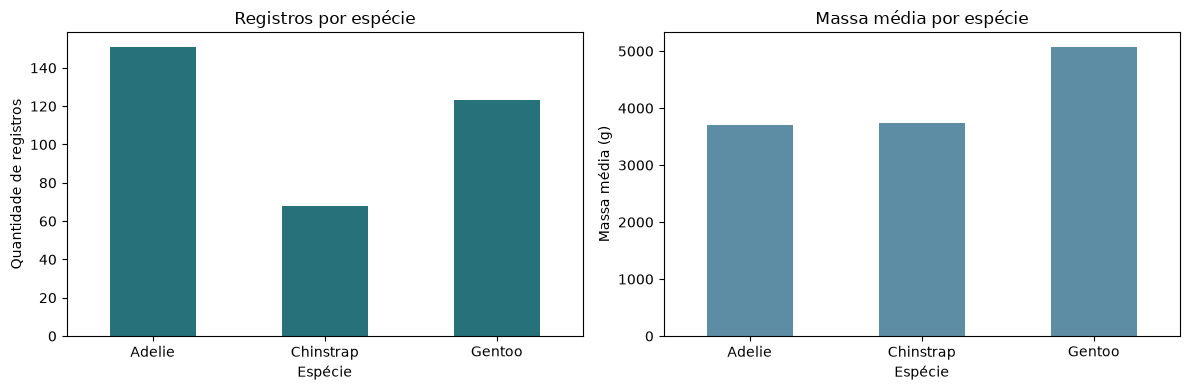

In [3]:
resumo_especie = (recorte.groupby("species", observed=True)
                  .agg(registros=("species", "size"), massa_media_g=("body_mass_g", "mean"),
                       nadadeira_media_mm=("flipper_length_mm", "mean")))
display(resumo_especie.round(2))
display(pd.crosstab(recorte["species"], recorte["island"]))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
resumo_especie["registros"].plot.bar(ax=axes[0], color="#27717a", rot=0)
axes[0].set(title="Registros por espécie", xlabel="Espécie", ylabel="Quantidade de registros")
resumo_especie["massa_media_g"].plot.bar(ax=axes[1], color="#5d8ca5", rot=0)
axes[1].set(title="Massa média por espécie", xlabel="Espécie", ylabel="Massa média (g)")
plt.tight_layout()
plt.show()

Na base completa, existem 342 registros; 123 são Gentoo (aproximadamente 36,0%). A média de massa para Gentoo é cerca de 5.076 g. As espécies não estão distribuídas de maneira igual entre as ilhas; portanto, diferenças entre ilhas não devem ser atribuídas ao local isoladamente.

Os cálculos do aplicativo usam os dados filtrados em cada interação. A justificativa detalhada está em `entregas/justificativa-metricas.md`.